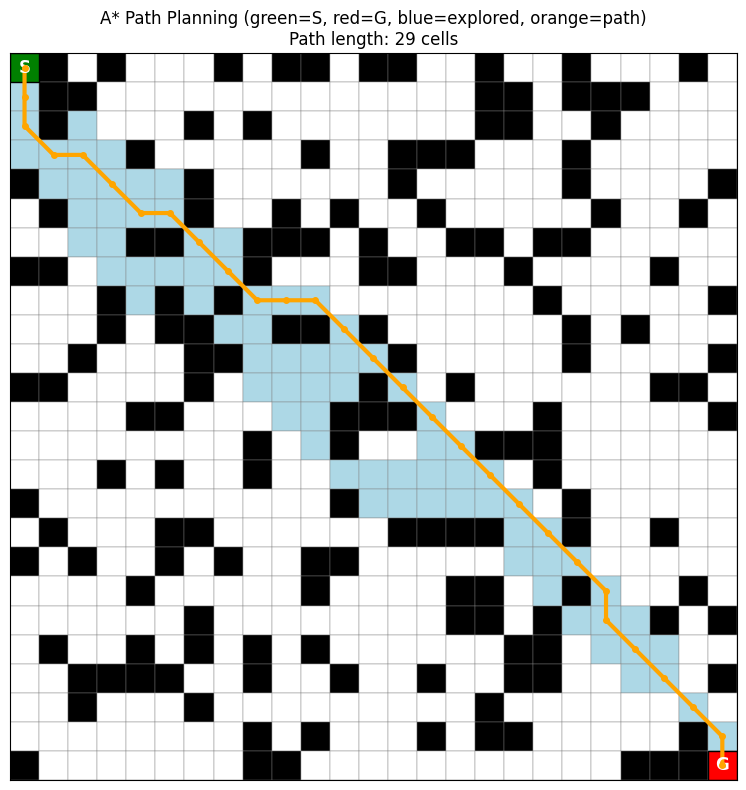

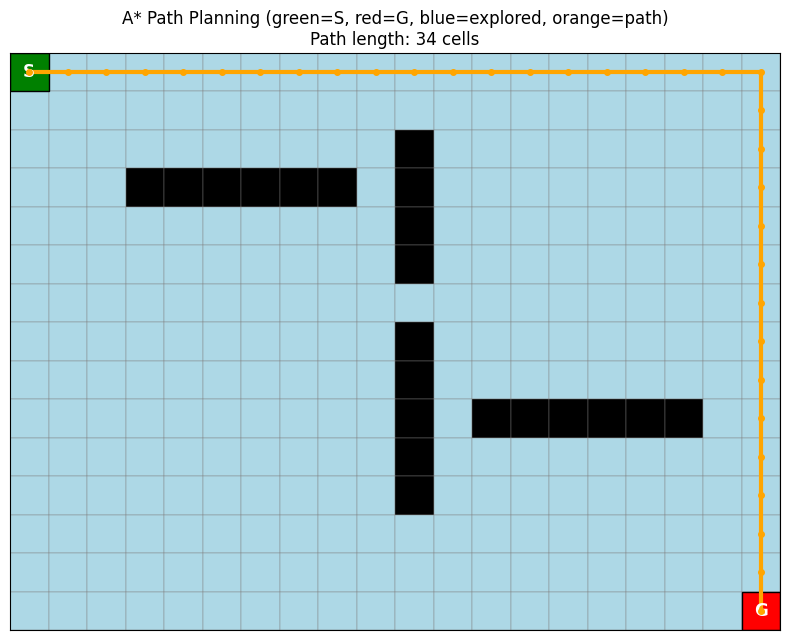

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from heapq import heappush, heappop
import random

# ---------------- A* Implementation ----------------
def astar(grid, start, goal, allow_diagonal=True):
    """
    A* path planning on a 2D grid.
    grid: 2D numpy array, 0 = free, 1 = obstacle
    start, goal: (row, col)
    Returns: path (list of (r,c)), visited set, cost dict
    """
    rows, cols = grid.shape

    # 8-connected or 4-connected moves
    if allow_diagonal:
        neighbors = [(-1,0),(1,0),(0,-1),(0,1),
                     (-1,-1),(-1,1),(1,-1),(1,1)]
    else:
        neighbors = [(-1,0),(1,0),(0,-1),(0,1)]

    def heuristic(a, b):
        # Octile distance for 8-conn, Manhattan for 4-conn
        dr, dc = abs(a[0]-b[0]), abs(a[1]-b[1])
        if allow_diagonal:
            return (dr + dc) + (np.sqrt(2) - 2) * min(dr, dc)
        return dr + dc

    def is_valid(r, c):
        return 0 <= r < rows and 0 <= c < cols and grid[r, c] == 0

    if not is_valid(*start) or not is_valid(*goal):
        print("Start or goal is invalid / on an obstacle.")
        return None, set(), {}

    open_heap = []
    heappush(open_heap, (heuristic(start, goal), 0.0, start))
    g_cost = {start: 0.0}
    came_from = {}
    closed = set()
    visited_order = []  # for visualization

    while open_heap:
        _, g, current = heappop(open_heap)
        if current in closed:
            continue
        closed.add(current)
        visited_order.append(current)

        if current == goal:
            # reconstruct path
            path = [current]
            while current in came_from:
                current = came_from[current]
                path.append(current)
            path.reverse()
            return path, visited_order, g_cost

        for dr, dc in neighbors:
            nr, nc = current[0] + dr, current[1] + dc
            if not is_valid(nr, nc):
                continue
            step = np.sqrt(2) if (dr != 0 and dc != 0) else 1.0
            new_g = g + step
            nbr = (nr, nc)
            if new_g < g_cost.get(nbr, float('inf')):
                g_cost[nbr] = new_g
                came_from[nbr] = current
                f = new_g + heuristic(nbr, goal)
                heappush(open_heap, (f, new_g, nbr))

    print("No path found.")
    return None, visited_order, g_cost

# ---------------- Visualization ----------------
def visualize(grid, start, goal, path, visited):
    fig, ax = plt.subplots(figsize=(8, 8))
    rows, cols = grid.shape

    # Draw grid cells
    for r in range(rows):
        for c in range(cols):
            if grid[r, c] == 1:
                color = 'black'
            elif (r, c) in visited:
                color = 'lightblue'
            else:
                color = 'white'
            ax.add_patch(patches.Rectangle((c, rows-1-r), 1, 1,
                                           facecolor=color,
                                           edgecolor='gray',
                                           linewidth=0.3))

    # Draw path
    if path is not None and len(path) > 0:
        ys = [rows - 1 - p[0] + 0.5 for p in path]
        xs = [p[1] + 0.5 for p in path]
        ax.plot(xs, ys, '-', color='orange', linewidth=3, zorder=3)
        ax.plot(xs, ys, 'o', color='orange', markersize=4, zorder=4)

    # Start / Goal markers
    ax.add_patch(patches.Rectangle((start[1], rows-1-start[0]), 1, 1,
                                   facecolor='green', edgecolor='black'))
    ax.add_patch(patches.Rectangle((goal[1], rows-1-goal[0]), 1, 1,
                                   facecolor='red', edgecolor='black'))
    ax.text(start[1]+0.5, rows-1-start[0]+0.5, 'S', ha='center', va='center',
            fontsize=12, fontweight='bold', color='white')
    ax.text(goal[1]+0.5, rows-1-goal[0]+0.5, 'G', ha='center', va='center',
            fontsize=12, fontweight='bold', color='white')

    ax.set_xlim(0, cols)
    ax.set_ylim(0, rows)
    ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])
    title = "A* Path Planning (green=S, red=G, blue=explored, orange=path)"
    if path:
        title += f"\nPath length: {len(path)} cells"
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

# ---------------- Example Maze ----------------
def make_random_grid(rows, cols, obstacle_prob=0.25, seed=0):
    rng = random.Random(seed)
    grid = np.zeros((rows, cols), dtype=int)
    for r in range(rows):
        for c in range(cols):
            if rng.random() < obstacle_prob:
                grid[r, c] = 1
    return grid

# --- Demo 1: random obstacles ---
rows, cols = 25, 25
grid = make_random_grid(rows, cols, obstacle_prob=0.25, seed=42)
start, goal = (0, 0), (rows-1, cols-1)
grid[start] = 0
grid[goal] = 0

path, visited, _ = astar(grid, start, goal, allow_diagonal=True)
visualize(grid, start, goal, path, visited)

# --- Demo 2: handcrafted maze ---
grid2 = np.zeros((15, 20), dtype=int)
# vertical wall with a gap
grid2[2:12, 10] = 1
grid2[6, 10] = 0
# horizontal walls
grid2[3, 3:9] = 1
grid2[9, 12:18] = 1

start2, goal2 = (0, 0), (14, 19)
grid2[start2] = 0
grid2[goal2] = 0

path2, visited2, _ = astar(grid2, start2, goal2, allow_diagonal=False)
visualize(grid2, start2, goal2, path2, visited2)

Running Dijkstra's algorithm...
Recorded 71 frames
Path found: 20 cells (cost = 19)
Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9), (3, 9), (4, 9), (5, 9), (6, 9), (7, 9), (8, 9), (9, 9), (10, 9)]
GIF saved as dijkstra_grid.gif with 71 frames

Displaying GIF...


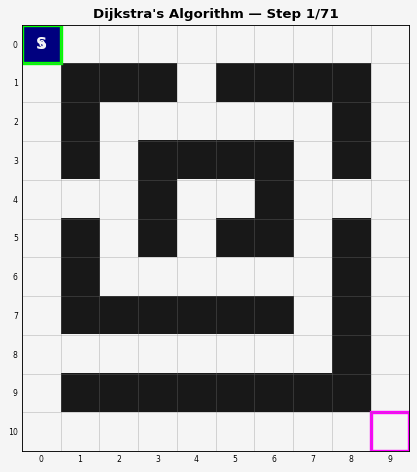

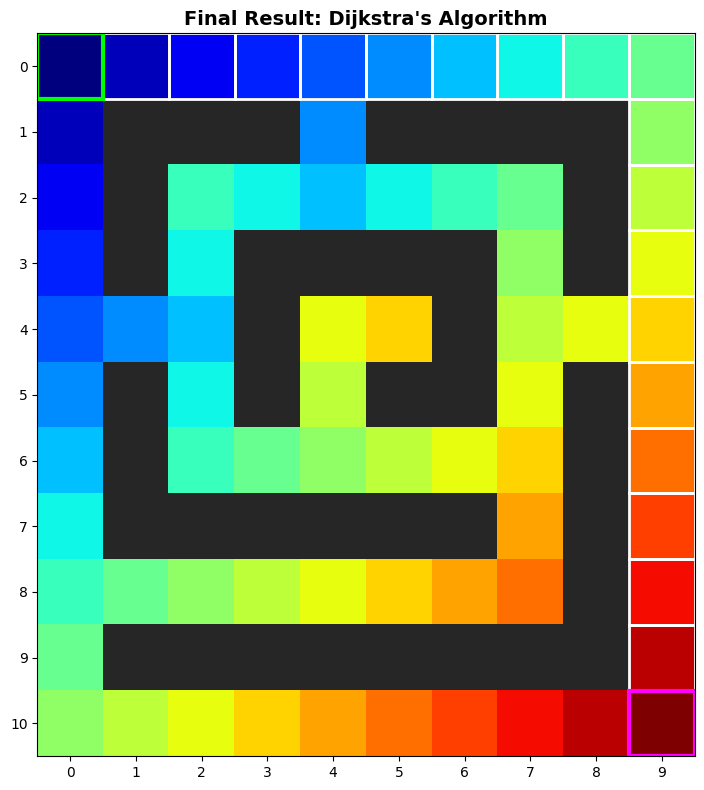

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
import heapq
from PIL import Image
import io

def dijkstra_with_frames(grid, start, goal):
    """
    Run Dijkstra's algorithm on a grid and record frames.

    Args:
        grid: 2D numpy array where 0 = free, 1 = obstacle
        start: (row, col) tuple
        goal: (row, col) tuple

    Returns:
        List of frames (each frame is a numpy array of costs or None)
        Final path
    """
    rows, cols = grid.shape

    # Distance array, initialized to infinity
    dist = np.full((rows, cols), np.inf)
    dist[start] = 0

    # Parent array for path reconstruction
    parent = {}

    # Priority queue: (cost, (row, col))
    pq = [(0, start)]
    visited = set()

    # Frames to record
    frames = []

    # Directions: up, down, left, right
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    # Record initial frame
    frames.append(dist.copy())

    while pq:
        current_dist, current = heapq.heappop(pq)

        if current in visited:
            continue

        visited.add(current)

        # If we reached the goal, we can stop (or continue to explore all)
        if current == goal:
            # Still record frame after goal reached
            frames.append(dist.copy())
            break

        r, c = current

        # Explore neighbors
        for dr, dc in directions:
            nr, nc = r + dr, c + dc

            # Check bounds
            if 0 <= nr < rows and 0 <= nc < cols:
                # Check obstacle
                if grid[nr, nc] == 1:
                    continue

                # Check if visited
                if (nr, nc) in visited:
                    continue

                new_dist = current_dist + 1  # uniform cost

                if new_dist < dist[nr, nc]:
                    dist[nr, nc] = new_dist
                    parent[(nr, nc)] = current
                    heapq.heappush(pq, (new_dist, (nr, nc)))

        # Record frame after processing this node
        frames.append(dist.copy())

    # Reconstruct path
    path = []
    if goal in visited or dist[goal] < np.inf:
        node = goal
        while node != start:
            path.append(node)
            if node not in parent:
                break
            node = parent[node]
        path.append(start)
        path.reverse()

    return frames, path, visited


def create_gif(frames, grid, start, goal, path, visited, filename='dijkstra_grid.gif', fps=5):
    """Create a GIF from the recorded frames."""

    # Prepare colormap: use a custom colormap for costs
    # Use a colormap that maps: obstacle=black, unexplored=light gray,
    # visited gradient from light blue to dark red
    rows, cols = grid.shape

    # Find max finite cost for normalization
    max_cost = 0
    for f in frames:
        finite = f[np.isfinite(f)]
        if len(finite) > 0:
            max_cost = max(max_cost, finite.max())
    max_cost = max(max_cost, 1)

    images = []

    for idx, frame in enumerate(frames):
        fig, ax = plt.subplots(figsize=(6, 6), dpi=80)

        # Create display array
        display = np.full((rows, cols, 3), 0.95)  # light gray background

        # Mark obstacles as black
        for r in range(rows):
            for c in range(cols):
                if grid[r, c] == 1:
                    display[r, c] = [0.1, 0.1, 0.1]  # dark for obstacles

        # Color explored cells by cost (color grading)
        # Blue (low cost) -> Yellow -> Red (high cost)
        cmap = plt.cm.jet

        for r in range(rows):
            for c in range(cols):
                if grid[r, c] == 1:
                    continue
                if np.isfinite(frame[r, c]):
                    # Normalize cost to [0, 1]
                    norm_cost = frame[r, c] / max_cost
                    color = cmap(norm_cost)[:3]
                    display[r, c] = color

        # Draw grid lines
        ax.imshow(display, interpolation='nearest')

        # Grid lines
        for r in range(rows + 1):
            ax.axhline(r - 0.5, color='gray', linewidth=0.5, alpha=0.5)
        for c in range(cols + 1):
            ax.axvline(c - 0.5, color='gray', linewidth=0.5, alpha=0.5)

        # Draw start and goal
        ax.add_patch(Rectangle((start[1] - 0.5, start[0] - 0.5), 1, 1,
                                fill=False, edgecolor='lime', linewidth=3))
        ax.text(start[1], start[0], 'S', ha='center', va='center',
                fontsize=14, fontweight='bold', color='white')

        ax.add_patch(Rectangle((goal[1] - 0.5, goal[0] - 0.5), 1, 1,
                                fill=False, edgecolor='magenta', linewidth=3))
        ax.text(goal[1], goal[0], 'G', ha='center', va='center',
                fontsize=14, fontweight='bold', color='white')

        # Show path if we're at the last frame
        if idx == len(frames) - 1 and path:
            for (pr, pc) in path:
                ax.add_patch(Rectangle((pc - 0.5, pr - 0.5), 1, 1,
                                        fill=False, edgecolor='white',
                                        linewidth=2, linestyle='--'))

        # Show cost values as text
        for r in range(rows):
            for c in range(cols):
                if grid[r, c] == 1:
                    continue
                if np.isfinite(frame[r, c]):
                    ax.text(c, r, f'{int(frame[r,c])}', ha='center', va='center',
                            fontsize=8, color='white', fontweight='bold')

        # Title
        if idx == len(frames) - 1:
            title = f"Dijkstra's Algorithm — Final (path length = {len(path)-1 if path else 'N/A'})"
        else:
            title = f"Dijkstra's Algorithm — Step {idx + 1}/{len(frames)}"
        ax.set_title(title, fontsize=12, fontweight='bold')

        ax.set_xticks(range(cols))
        ax.set_yticks(range(rows))
        ax.set_xticklabels([str(i) for i in range(cols)], fontsize=7)
        ax.set_yticklabels([str(i) for i in range(rows)], fontsize=7)
        ax.tick_params(length=0)

        plt.tight_layout()

        # Save to buffer
        buf = io.BytesIO()
        plt.savefig(buf, format='png', bbox_inches='tight')
        buf.seek(0)
        images.append(Image.open(buf).copy())
        plt.close(fig)
        buf.close()

    # Save as GIF
    if images:
        images[0].save(filename, save_all=True, append_images=images[1:],
                       duration=1000 // fps, loop=0)
        print(f"GIF saved as {filename} with {len(images)} frames")

    return filename


def main():
    # Create a grid world with obstacles
    # 0 = free, 1 = obstacle
    grid = np.array([
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 1, 1, 1, 0, 1, 1, 1, 1, 0],
        [0, 1, 0, 0, 0, 0, 0, 0, 1, 0],
        [0, 1, 0, 1, 1, 1, 1, 0, 1, 0],
        [0, 0, 0, 1, 0, 0, 1, 0, 0, 0],
        [0, 1, 0, 1, 0, 1, 1, 0, 1, 0],
        [0, 1, 0, 0, 0, 0, 0, 0, 1, 0],
        [0, 1, 1, 1, 1, 1, 1, 0, 1, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
        [0, 1, 1, 1, 1, 1, 1, 1, 1, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    ])

    start = (0, 0)
    goal = (10, 9)

    print("Running Dijkstra's algorithm...")
    frames, path, visited = dijkstra_with_frames(grid, start, goal)

    print(f"Recorded {len(frames)} frames")
    print(f"Path found: {len(path)} cells (cost = {len(path)-1})")
    print(f"Path: {path}")

    gif_file = create_gif(frames, grid, start, goal, path, visited,
                           filename='dijkstra_grid.gif', fps=4)

    # Display the GIF
    print("\nDisplaying GIF...")
    from IPython.display import Image as IPImage, display
    try:
        display(IPImage(filename=gif_file))
    except Exception:
        # If not in Jupyter, try to open with PIL
        img = Image.open(gif_file)
        img.show()

    # Also display a final static frame
    fig, ax = plt.subplots(figsize=(8, 8))
    rows, cols = grid.shape

    max_cost = max(f[np.isfinite(f)].max() for f in frames if np.any(np.isfinite(f)))

    display_arr = np.zeros((rows, cols, 3))
    for r in range(rows):
        for c in range(cols):
            if grid[r, c] == 1:
                display_arr[r, c] = [0.15, 0.15, 0.15]
            elif np.isfinite(frames[-1][r, c]):
                display_arr[r, c] = plt.cm.jet(frames[-1][r, c] / max_cost)[:3]
            else:
                display_arr[r, c] = [0.95, 0.95, 0.95]

    ax.imshow(display_arr, interpolation='nearest')

    for pr, pc in path:
        ax.add_patch(Rectangle((pc - 0.5, pr - 0.5), 1, 1,
                                fill=False, edgecolor='white', linewidth=2))

    ax.add_patch(Rectangle((start[1] - 0.5, start[0] - 0.5), 1, 1,
                            fill=False, edgecolor='lime', linewidth=3))
    ax.add_patch(Rectangle((goal[1] - 0.5, goal[0] - 0.5), 1, 1,
                            fill=False, edgecolor='magenta', linewidth=3))

    ax.set_title('Final Result: Dijkstra\'s Algorithm', fontsize=14, fontweight='bold')
    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    plt.tight_layout()
    plt.savefig('dijkstra_final.png', dpi=100, bbox_inches='tight')
    plt.show()


if __name__ == "__main__":
    main()

In [ ]:
"""
Animated value iteration for shortest-path planning on a grid.

Saves 'value_iteration.gif' showing how the cost-to-go map evolves,
with the converged optimal policy drawn as arrows.
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

# ----------------------------------------------------------------------------
# 1. Build the grid world
# ----------------------------------------------------------------------------
N_ROWS, N_COLS = 12, 16
START = (1, 1)
GOAL  = (10, 14)

# Obstacles (rows, cols) — a few walls, a room, and a trap
OBSTACLES = set()
OBSTACLES |= {(r, 8) for r in range(0, 8)}                 # vertical wall
OBSTACLES |= {(5, c) for c in range(10, 15)}               # horizontal wall
OBSTACLES |= {(r, c) for r in range(2, 5) for c in range(3, 6)}  # room walls
OBSTACLES |= {(8, c) for c in range(2, 7)}                 # bottom wall

# ----------------------------------------------------------------------------
# 2. Value iteration
# ----------------------------------------------------------------------------
MOVES = ((-1, 0), (1, 0), (0, -1), (0, 1))  # up, down, left, right
STEP_COST = 1.0
GAMMA = 1.0
TOL = 1e-6
MAX_ITER = 400
INF = 1e9

def value_iteration():
    V = np.full((N_ROWS, N_COLS), INF)
    V[GOAL] = 0.0
    history = [V.copy()]

    for it in range(MAX_ITER):
        V_new = V.copy()
        delta = 0.0
        for r in range(N_ROWS):
            for c in range(N_COLS):
                if (r, c) == GOAL or (r, c) in OBSTACLES:
                    continue
                best = INF
                for dr, dc in MOVES:
                    nr, nc = r + dr, c + dc
                    if 0 <= nr < N_ROWS and 0 <= nc < N_COLS and (nr, nc) not in OBSTACLES:
                        best = min(best, STEP_COST + GAMMA * V[nr, nc])
                V_new[r, c] = best
                delta = max(delta, abs(V_new[r, c] - V[r, c]))
        V = V_new
        history.append(V.copy())
        if delta < TOL:
            break
    return history

print("Running value iteration...")
HISTORY = value_iteration()
print(f"Converged after {len(HISTORY) - 1} iterations.")

# ----------------------------------------------------------------------------
# 3. Recover the optimal policy from the final V
# ----------------------------------------------------------------------------
V_final = HISTORY[-1]
POLICY = np.full((N_ROWS, N_COLS), None, dtype=object)  # store (dr, dc)

for r in range(N_ROWS):
    for c in range(N_COLS):
        if (r, c) == GOAL or (r, c) in OBSTACLES:
            continue
        best_val, best_move = INF, None
        for dr, dc in MOVES:
            nr, nc = r + dr, c + dc
            if 0 <= nr < N_ROWS and 0 <= nc < N_COLS and (nr, nc) not in OBSTACLES:
                v = STEP_COST + GAMMA * V_final[nr, nc]
                if v < best_val:
                    best_val, best_move = v, (dr, dc)
        POLICY[r, c] = best_move

# ----------------------------------------------------------------------------
# 4. Figure setup
# ----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 7))
ax.set_title("Value Iteration — Cost-to-Go")
ax.set_xticks(np.arange(-0.5, N_COLS, 1), minor=True)
ax.set_yticks(np.arange(-0.5, N_ROWS, 1), minor=True)
ax.grid(which="minor", color="lightgray", linewidth=0.5)
ax.set_xticks([])
ax.set_yticks([])

# Mask obstacles as NaN so they get a distinct color from cmap
def masked_for_display(V):
    Vm = V.copy().astype(float)
    for (r, c) in OBSTACLES:
        Vm[r, c] = np.nan
    return Vm

# Use a colormap that handles NaN nicely
cmap = plt.cm.viridis.copy()
cmap.set_bad(color="dimgray")

# Determine max finite value for consistent color scale across frames
finite_vals = [HISTORY[-1][r, c] for r in range(N_ROWS) for c in range(N_COLS)
               if HISTORY[-1][r, c] < INF and (r, c) not in OBSTACLES]
VMAX = max(finite_vals) if finite_vals else 1.0

im = ax.imshow(masked_for_display(HISTORY[0]), cmap=cmap,
               vmin=0, vmax=VMAX, origin="upper")
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Cost-to-go (steps to goal)")

# Text annotations for values
texts = np.empty((N_ROWS, N_COLS), dtype=object)
for r in range(N_ROWS):
    for c in range(N_COLS):
        if (r, c) in OBSTACLES:
            continue
        texts[r, c] = ax.text(c, r, "", ha="center", va="center",
                              fontsize=7, color="white")

# Policy arrows (drawn on final frame)
arrows = []
def draw_policy():
    for r in range(N_ROWS):
        for c in range(N_COLS):
            if (r, c) in OBSTACLES or (r, c) == GOAL:
                continue
            mv = POLICY[r, c]
            if mv is None:
                continue
            dr, dc = mv
            arr = ax.annotate("", xy=(c + 0.35 * dc, r + 0.35 * dr),
                              xytext=(c - 0.25 * dc, r - 0.25 * dr),
                              arrowprops=dict(arrowstyle="->", color="black", lw=1.2))
            arrows.append(arr)

# Start / goal markers
ax.scatter([START[1]], [START[0]], marker="o", s=180, facecolor="lime",
           edgecolor="black", zorder=5, label="Start")
ax.scatter([GOAL[1]], [GOAL[0]], marker="*", s=300, facecolor="gold",
           edgecolor="black", zorder=5, label="Goal")
ax.legend(loc="upper right", framealpha=0.9)

# ----------------------------------------------------------------------------
# 5. Animation update
# ----------------------------------------------------------------------------
def update(frame):
    V = HISTORY[frame]
    im.set_array(masked_for_display(V))
    ax.set_title(f"Value Iteration — Cost-to-Go  (iteration {frame}/{len(HISTORY)-1})")
    for r in range(N_ROWS):
        for c in range(N_COLS):
            if (r, c) in OBSTACLES or texts[r, c] is None:
                continue
            v = V[r, c]
            if v >= INF * 0.5:
                texts[r, c].set_text("∞")
                texts[r, c].set_color("lightgray")
            else:
                texts[r, c].set_text(f"{v:.0f}")
                texts[r, c].set_color("white" if v < VMAX * 0.6 else "black")
    # Draw policy arrows on the last few frames
    for arr in arrows:
        arr.remove()
    arrows.clear()
    if frame == len(HISTORY) - 1:
        draw_policy()
    return [im] + [t for t in texts.flat if t is not None]

# A few extra frames at the end so the policy arrows are visible
FRAMES = list(range(len(HISTORY))) + [len(HISTORY) - 1] * 15

anim = FuncAnimation(fig, update, frames=FRAMES, interval=120, blit=False)
anim.save("value_iteration.gif", writer=PillowWriter(fps=8))
print("Saved value_iteration.gif")
plt.close(fig)

Running value iteration...
Converged after 25 iterations.
Saved value_iteration.gif


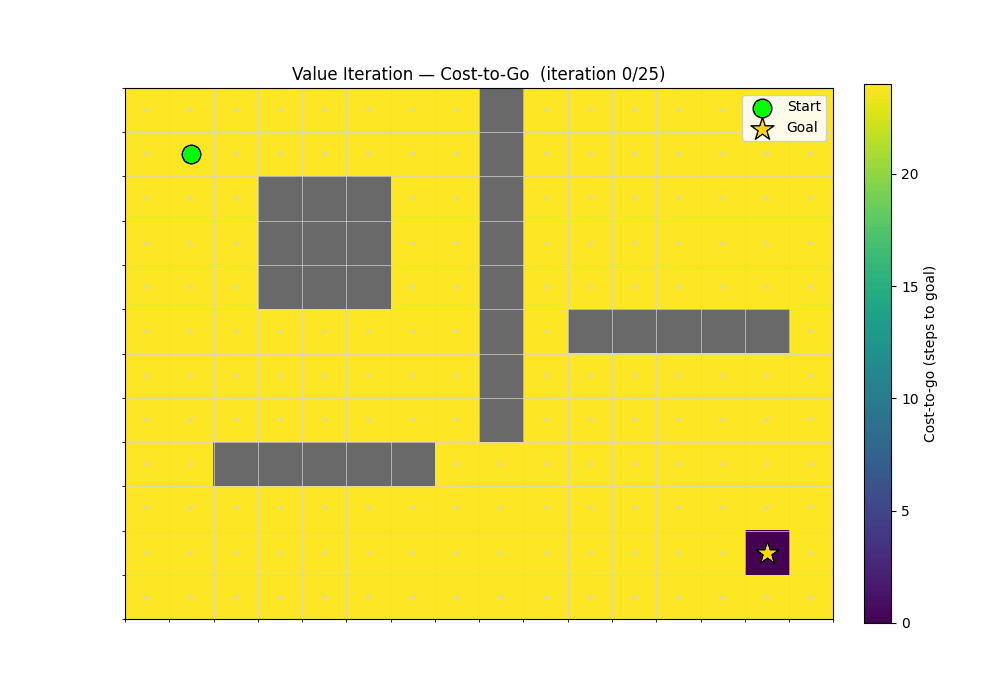

In [ ]:
from IPython.display import Image, display

display(Image(filename="value_iteration.gif"))